In [12]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.15
CV_FOLDS = 3
TFIDF_MAX_FEATURES = 5000

pd.set_option("display.max_columns", 50)

print("All libraries imported successfully.")

All libraries imported successfully.


In [13]:
DATA_PATH = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week4_feature_engineered_reviews.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Please check the file path."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully.
Dataset shape: (116137, 30)


,unnamed_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd,review_length_chars,length_outlier,review_text_clean,review_word_count,sentence_count,exclamation_count,question_count,uppercase_ratio,rating_group,concern_keyword_count,benefit_keyword_count
0,0,2079014373,5,1.0,NaN,0,0,0,2023-03-14,These are the only pimple patches I’ve used th...,Best Pimple Patches,medium,blue,normal,NaN,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0,80,False,These are the only pimple patches I’ve used th...,14,2,0,0,0.030769,High,0,0
1,1,12631885517,4,1.0,NaN,0,0,0,2023-02-08,One of my ingrown hair turned inflamed and sor...,It works!,mediumtan,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0,264,False,One of my ingrown hair turned inflamed and sor...,45,5,0,0,0.018779,High,0,0
2,2,2321761961,5,1.0,1.0,1,0,1,2023-02-05,I have tried 10 different acne/blemish patches...,Good for a large or painful breakout! Sleep in...,NaN,hazel,combination,blonde,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0,1066,True,I have tried 10 different acne/blemish patches...,198,14,1,0,0.022892,High,6,0
3,3,1380382883,4,1.0,NaN,0,0,0,2023-01-24,"Love these for my mid-size breakouts, specifyi...",Micro tips are a plus!!,light,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0,123,False,"Love these for my mid-size breakouts, specifyi...",20,2,2,0,0.010000,High,1,0
4,4,8871759068,4,1.0,1.0,1,0,1,2023-01-15,Best so far - though still not particularly ef...,NaN,NaN,NaN,NaN,NaN,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0,127,False,Best so far - though still not particularly ef...,22,2,0,0,0.019802,High,0,0



Column names:
['unnamed_0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'review_length_chars', 'length_outlier', 'review_text_clean', 'review_word_count', 'sentence_count', 'exclamation_count', 'question_count', 'uppercase_ratio', 'rating_group', 'concern_keyword_count', 'benefit_keyword_count']


In [14]:
if "review_text_clean" in df.columns:
    TEXT_COLUMN = "review_text_clean"
elif "review_text" in df.columns:
    TEXT_COLUMN = "review_text"
else:
    raise KeyError(
        "Neither review_text_clean nor review_text was found."
    )

if "rating" not in df.columns:
    raise KeyError("The rating column was not found.")

df["rating"] = pd.to_numeric(
    df["rating"], errors="coerce"
)

df[TEXT_COLUMN] = (
    df[TEXT_COLUMN]
    .fillna("")
    .astype(str)
    .str.strip()
)

valid_mask = (
    df["rating"].between(1, 5)
    & df[TEXT_COLUMN].ne("")
)

model_df = df.loc[
    valid_mask, [TEXT_COLUMN, "rating"]
].copy()

model_df["target"] = np.select(
    [
        model_df["rating"].between(1, 2),
        model_df["rating"].eq(3),
        model_df["rating"].between(4, 5)
    ],
    ["Low", "Medium", "High"],
    default="Invalid"
)

model_df = model_df[
    model_df["target"].isin(["Low", "Medium", "High"])
].reset_index(drop=True)

X = model_df[TEXT_COLUMN]
y = model_df["target"]

CLASS_ORDER = ["Low", "Medium", "High"]

print("Selected text column:", TEXT_COLUMN)
print("Total usable reviews:", len(model_df))
print("Excluded rows:", len(df) - len(model_df))

Selected text column: review_text_clean
Total usable reviews: 116137
Excluded rows: 0


In [15]:
class_counts = y.value_counts().reindex(
    CLASS_ORDER, fill_value=0
)

class_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Review_Count": class_counts.values,
    "Percentage": (
        class_counts.values / class_counts.sum() * 100
    ).round(2)
})

display(class_summary)

,Class,Review_Count,Percentage
0,Low,12175,10.48
1,Medium,8662,7.46
2,High,95300,82.06


In [16]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Development samples:", len(X_dev))
print("Test samples:", len(X_test))

print("\nDevelopment class distribution:")
display(
    (
        y_dev.value_counts(normalize=True)
        .reindex(CLASS_ORDER) * 100
    ).round(2).rename("Percentage").to_frame()
)

print("\nTest class distribution:")
display(
    (
        y_test.value_counts(normalize=True)
        .reindex(CLASS_ORDER) * 100
    ).round(2).rename("Percentage").to_frame()
)

Development samples: 98716
Test samples: 17421

Development class distribution:


,Percentage
target,
Low,10.48
Medium,7.46
High,82.06



Test class distribution:


,Percentage
target,
Low,10.48
Medium,7.46
High,82.06


In [17]:
def make_text_pipeline(classifier):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=TFIDF_MAX_FEATURES,
                ngram_range=(1, 2),
                min_df=3,
                sublinear_tf=True,
                strip_accents="unicode",
                lowercase=True
            )
        ),
        ("classifier", classifier)
    ])


models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": make_text_pipeline(
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),

    "LinearSVC": make_text_pipeline(
        LinearSVC(
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),

    "Multinomial Naive Bayes": make_text_pipeline(
        MultinomialNB(alpha=1.0)
    )
}

print("Models ready for evaluation:")
for model_name in models:
    print("-", model_name)

Models ready for evaluation:
- Majority baseline
- Logistic Regression
- LinearSVC
- Multinomial Naive Bayes


In [18]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_precision": "precision_macro",
    "macro_recall": "recall_macro",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for model_name, estimator in models.items():

    print(f"Evaluating: {model_name}")

    scores = cross_validate(
        estimator,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
        error_score="raise"
    )

    row = {"model": model_name}

    for metric_name in scoring:

        fold_scores = scores[f"test_{metric_name}"]

        row[f"{metric_name}_mean"] = np.mean(
            fold_scores
        )

        row[f"{metric_name}_std"] = np.std(
            fold_scores,
            ddof=1
        )

    row["mean_fit_time_seconds"] = np.mean(
        scores["fit_time"]
    )

    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)

cv_results = cv_results.sort_values(
    "macro_f1_mean",
    ascending=False
).reset_index(drop=True)

print("\nCross-validation results:")
display(cv_results.round(4))

Evaluating: Majority baseline
Evaluating: Logistic Regression
Evaluating: LinearSVC
Evaluating: Multinomial Naive Bayes

Cross-validation results:


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,mean_fit_time_seconds
0,LinearSVC,0.8813,0.0003,0.7143,0.0042,0.6814,0.0023,0.7143,0.0042,0.6965,0.0031,0.8857,0.0004,17.1309
1,Logistic Regression,0.8425,0.0021,0.7490,0.0040,0.6473,0.0030,0.7490,0.0040,0.6798,0.0034,0.8622,0.0014,19.2780
2,Multinomial Naive Bayes,0.8715,0.0005,0.5199,0.0010,0.7400,0.0122,0.5199,0.0010,0.5578,0.0025,0.8397,0.0006,11.8948
3,Majority baseline,0.8206,0.0000,0.3333,0.0000,0.2735,0.0000,0.3333,0.0000,0.3005,0.0000,0.7397,0.0000,0.0778


In [19]:
eligible_models = cv_results[
    cv_results["model"] != "Majority baseline"
].copy()

if eligible_models.empty:
    raise RuntimeError("No trained model completed evaluation.")

selected_model_name = eligible_models.iloc[0]["model"]
selected_model = models[selected_model_name]

print("Selected model:", selected_model_name)
print("Selection metric: Mean cross-validated macro-F1")
print(
    "Mean CV macro-F1:",
    round(
        eligible_models.iloc[0]["macro_f1_mean"],
        4
    )
)

Selected model: LinearSVC
Selection metric: Mean cross-validated macro-F1
Mean CV macro-F1: 0.6965


In [20]:
from sklearn.base import clone

final_model = clone(selected_model)

final_model.fit(X_dev, y_dev)

y_pred = final_model.predict(X_test)

print("Selected model trained successfully.")
print("Test predictions generated:", len(y_pred))

Selected model trained successfully.
Test predictions generated: 17421


In [21]:
test_metrics = {
    "Selected_Model": selected_model_name,
    "Test_Samples": len(y_test),

    "Accuracy": accuracy_score(
        y_test, y_pred
    ),

    "Balanced_Accuracy": balanced_accuracy_score(
        y_test, y_pred
    ),

    "Macro_Precision": precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro_Recall": recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro_F1": f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
}

test_metrics_df = pd.DataFrame(
    [test_metrics]
)

display(test_metrics_df.round(4))

,Selected_Model,Test_Samples,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,LinearSVC,17421,0.8858,0.7284,0.693,0.7284,0.7091,0.8905


In [22]:
report_dict = classification_report(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame([
    {
        "Class": cls,
        "Precision": report_dict[cls]["precision"],
        "Recall": report_dict[cls]["recall"],
        "F1_Score": report_dict[cls]["f1-score"],
        "Support": int(report_dict[cls]["support"])
    }
    for cls in CLASS_ORDER
])

display(per_class_df.round(4))

print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=CLASS_ORDER,
        zero_division=0
    )
)

,Class,Precision,Recall,F1_Score,Support
0,Low,0.7151,0.7656,0.7395,1826
1,Medium,0.3992,0.4819,0.4367,1299
2,High,0.9647,0.9378,0.9511,14296



Detailed classification report:
              precision    recall  f1-score   support

         Low       0.72      0.77      0.74      1826
      Medium       0.40      0.48      0.44      1299
        High       0.96      0.94      0.95     14296

    accuracy                           0.89     17421
   macro avg       0.69      0.73      0.71     17421
weighted avg       0.90      0.89      0.89     17421



In [23]:
final_classifier = final_model.named_steps["classifier"]

if hasattr(final_classifier, "predict_proba"):
    raw_scores = final_model.predict_proba(X_test)
else:
    raw_scores = final_model.decision_function(X_test)

model_classes = list(final_classifier.classes_)

roc_data = {}
auc_rows = []

for cls in CLASS_ORDER:

    class_index = model_classes.index(cls)

    binary_truth = (
        np.asarray(y_test) == cls
    ).astype(int)

    class_scores = raw_scores[:, class_index]

    auc_value = roc_auc_score(
        binary_truth,
        class_scores
    )

    fpr, tpr, thresholds = roc_curve(
        binary_truth,
        class_scores
    )

    roc_data[cls] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc_value
    }

    auc_rows.append({
        "Class": cls,
        "One_vs_Rest_ROC_AUC": auc_value
    })

auc_df = pd.DataFrame(auc_rows)

macro_auc = auc_df[
    "One_vs_Rest_ROC_AUC"
].mean()

print("ROC-AUC by class:")
display(auc_df.round(4))

print("Macro one-vs-rest ROC-AUC:", round(macro_auc, 4))

ROC-AUC by class:


,Class,One_vs_Rest_ROC_AUC
0,Low,0.9677
1,Medium,0.8778
2,High,0.9616


Macro one-vs-rest ROC-AUC: 0.9357


In [24]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=CLASS_ORDER
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{cls}" for cls in CLASS_ORDER],
    columns=[f"Predicted_{cls}" for cls in CLASS_ORDER]
)

display(cm_df)

,Predicted_Low,Predicted_Medium,Predicted_High
Actual_Low,1398,298,130
Actual_Medium,312,626,361
Actual_High,245,644,13407


In [25]:
OUTPUT_DIR = DATA_PATH.parent / "week6_outputs"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

cv_results.to_csv(
    OUTPUT_DIR / "week6_cross_validation_results.csv",
    index=False
)

test_metrics_df.to_csv(
    OUTPUT_DIR / "week6_final_test_metrics.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "week6_per_class_metrics.csv",
    index=False
)

auc_df.to_csv(
    OUTPUT_DIR / "week6_roc_auc_results.csv",
    index=False
)

cm_df.to_csv(
    OUTPUT_DIR / "week6_confusion_matrix.csv"
)

print("Results tables saved to:")
print(OUTPUT_DIR)

Results tables saved to:
C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week6_outputs


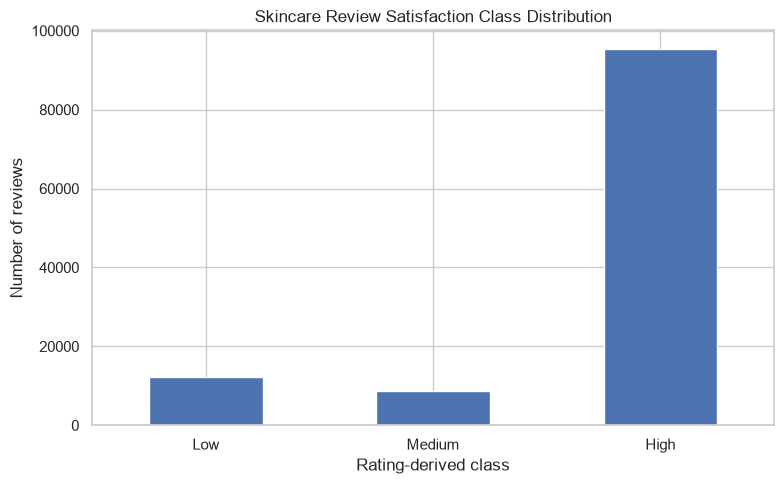

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))

class_counts.reindex(CLASS_ORDER).plot(
    kind="bar",
    ax=ax
)

ax.set_title("Skincare Review Satisfaction Class Distribution")
ax.set_xlabel("Rating-derived class")
ax.set_ylabel("Number of reviews")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

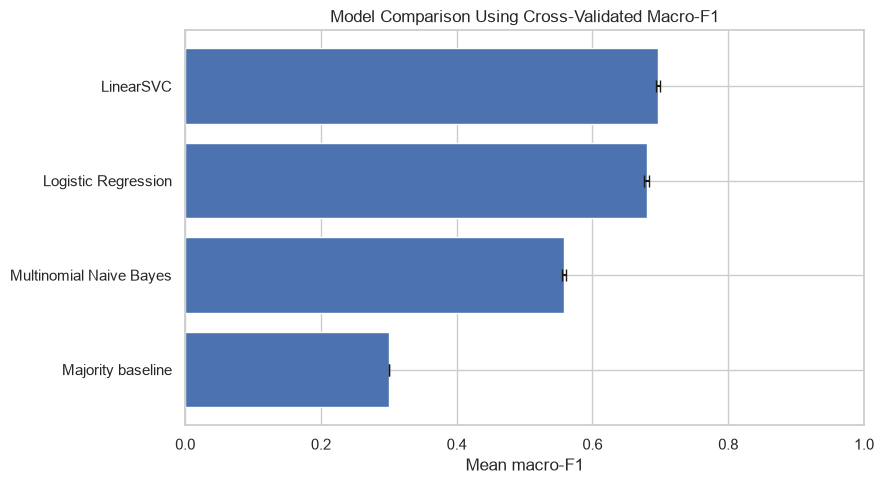

In [27]:
plot_df = cv_results.sort_values(
    "macro_f1_mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    plot_df["model"],
    plot_df["macro_f1_mean"],
    xerr=plot_df["macro_f1_std"],
    capsize=4
)

ax.set_title("Model Comparison Using Cross-Validated Macro-F1")
ax.set_xlabel("Mean macro-F1")
ax.set_xlim(0, 1)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

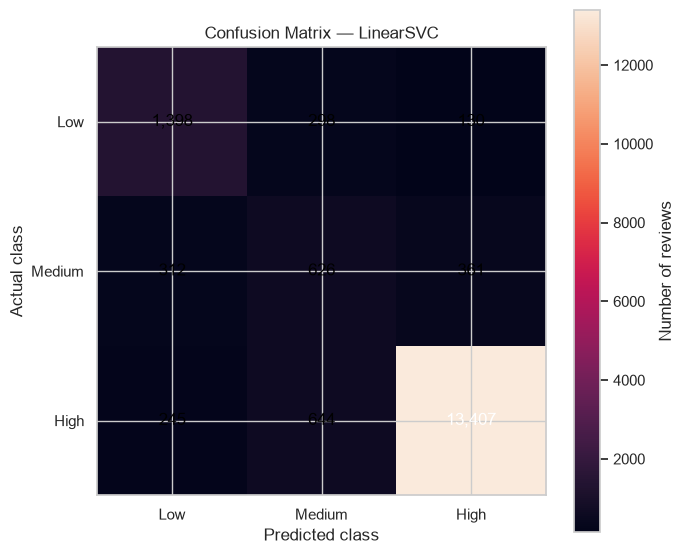

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))

image = ax.imshow(cm, interpolation="nearest")

ax.set_title(
    f"Confusion Matrix — {selected_model_name}"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

ax.set_xticks(range(len(CLASS_ORDER)))
ax.set_xticklabels(CLASS_ORDER)

ax.set_yticks(range(len(CLASS_ORDER)))
ax.set_yticklabels(CLASS_ORDER)

fig.colorbar(image, ax=ax, label="Number of reviews")

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

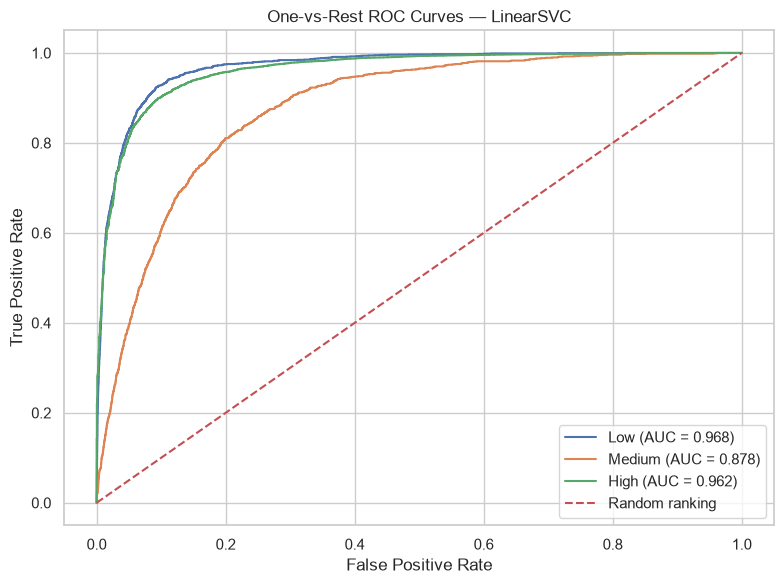

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))

for cls in CLASS_ORDER:

    ax.plot(
        roc_data[cls]["fpr"],
        roc_data[cls]["tpr"],
        label=(
            f"{cls} "
            f"(AUC = {roc_data[cls]['auc']:.3f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

ax.set_title(
    f"One-vs-Rest ROC Curves — {selected_model_name}"
)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_roc_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [30]:
prediction_df = pd.DataFrame({
    "review_text": X_test.reset_index(drop=True),
    "actual_class": y_test.reset_index(drop=True),
    "predicted_class": pd.Series(y_pred).reset_index(drop=True)
})

prediction_df["correct_prediction"] = (
    prediction_df["actual_class"]
    == prediction_df["predicted_class"]
)

prediction_df["is_error"] = (
    ~prediction_df["correct_prediction"]
)

error_summary = (
    prediction_df
    .groupby("actual_class", as_index=False)
    .agg(
        test_reviews=("actual_class", "size"),
        errors=("is_error", "sum")
    )
)

error_summary["error_rate"] = (
    error_summary["errors"]
    / error_summary["test_reviews"]
)

error_summary["error_rate_percentage"] = (
    error_summary["error_rate"] * 100
).round(2)

display(error_summary)

errors_df = prediction_df[
    ~prediction_df["correct_prediction"]
].copy()

print("Sample misclassified reviews:")
display(
    errors_df[
        [
            "review_text",
            "actual_class",
            "predicted_class"
        ]
    ].head(10)
)

error_summary.to_csv(
    OUTPUT_DIR / "week6_error_analysis_by_class.csv",
    index=False
)

errors_df.to_csv(
    OUTPUT_DIR / "week6_misclassified_reviews.csv",
    index=False
)

,actual_class,test_reviews,errors,error_rate,error_rate_percentage
0,High,14296,889,0.062185,6.22
1,Low,1826,428,0.234392,23.44
2,Medium,1299,673,0.518091,51.81


Sample misclassified reviews:


,review_text,actual_class,predicted_class
9,so far it burns my skin using it everyday. I w...,High,Medium
13,so these smell horrible... butttt I’ve used th...,High,Low
26,I was so excited to receive this eye cream bec...,High,Medium
29,I bought this product to compare it to Ilia’s ...,Medium,Low
37,I’m pretty light toned but the harsh orange of...,Medium,Low
41,This product delivers on the claim that it ins...,High,Medium
49,Does a great job protecting and priming your s...,High,Low
50,"Unfortunately, I’m going to return this. It fe...",Medium,Low
52,I got this as a deluxe sample. I have HUGE vis...,High,Low
73,Got a sample size of this product in the Sepho...,Low,Medium


In [31]:
metadata = {
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Predict rating-derived satisfaction categories",
    "target_definition": {
        "Low": "Ratings 1-2",
        "Medium": "Rating 3",
        "High": "Ratings 4-5"
    },
    "input_feature": "Review text only",
    "text_column": TEXT_COLUMN,
    "test_size": TEST_SIZE,
    "cross_validation_folds": CV_FOLDS,
    "random_state": RANDOM_STATE,
    "tfidf_max_features": TFIDF_MAX_FEATURES,
    "selected_model": selected_model_name,
    "final_test_metrics": {
        key: (
            float(value)
            if isinstance(value, (np.integer, np.floating))
            else value
        )
        for key, value in test_metrics.items()
    },
    "macro_ovr_roc_auc": float(macro_auc),
    "limitations": [
        "The target categories are derived from star ratings.",
        "Results do not independently validate sentiment labels.",
        "Business impact has not been experimentally measured."
    ]
}

with open(
    OUTPUT_DIR / "week6_evaluation_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

print("Evaluation metadata saved.")

Evaluation metadata saved.


In [32]:
print("=" * 60)
print("WEEK 6: MODEL EVALUATION SUMMARY")
print("=" * 60)

print("Selected model:", selected_model_name)
print("Test samples:", len(y_test))
print()

print("FINAL TEST METRICS")

for metric in [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_F1"
]:
    print(
        f"{metric}: {test_metrics[metric]:.4f}"
    )

print(f"Macro ROC-AUC: {macro_auc:.4f}")

print("\nOUTPUT FILES")

for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)

print("\nWeek 6 evaluation completed successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

WEEK 6: MODEL EVALUATION SUMMARY
Selected model: LinearSVC
Test samples: 17421

FINAL TEST METRICS
Accuracy: 0.8858
Balanced_Accuracy: 0.7284
Macro_Precision: 0.6930
Macro_Recall: 0.7284
Macro_F1: 0.7091
Weighted_F1: 0.8905
Macro ROC-AUC: 0.9357

OUTPUT FILES
week6_class_distribution.png
week6_confusion_matrix.csv
week6_confusion_matrix.png
week6_cross_validation_results.csv
week6_error_analysis_by_class.csv
week6_evaluation_metadata.json
week6_final_test_metrics.csv
week6_misclassified_reviews.csv
week6_model_comparison.png
week6_per_class_metrics.csv
week6_roc_auc_results.csv
week6_roc_curves.png

Week 6 evaluation completed successfully.
Output folder: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week6_outputs


In [33]:
OUTPUT_DIR = DATA_PATH.parent / "week6_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(
    OUTPUT_DIR / "week6_cross_validation_results.csv",
    index=False
)

test_metrics_df.to_csv(
    OUTPUT_DIR / "week6_final_test_metrics.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "week6_per_class_metrics.csv",
    index=False
)

auc_df.to_csv(
    OUTPUT_DIR / "week6_roc_auc_results.csv",
    index=False
)

cm_df.to_csv(
    OUTPUT_DIR / "week6_confusion_matrix.csv"
)

print("Evaluation tables saved to:", OUTPUT_DIR)

Evaluation tables saved to: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week6_outputs


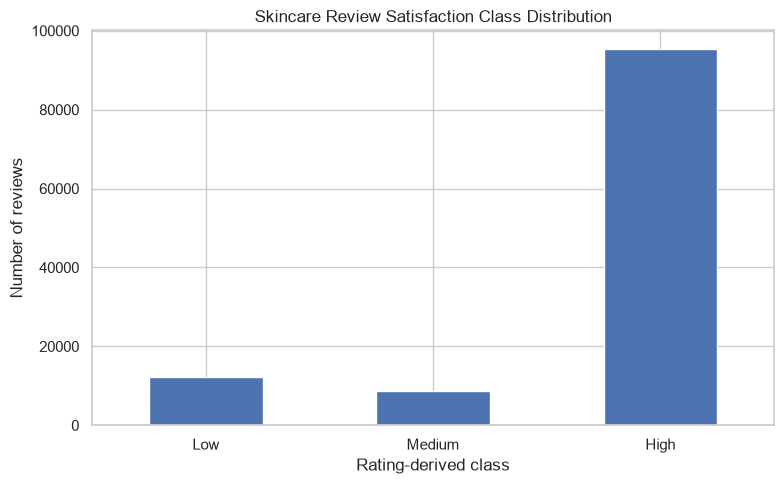

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))

class_counts.reindex(CLASS_ORDER).plot(
    kind="bar",
    ax=ax
)

ax.set_title("Skincare Review Satisfaction Class Distribution")
ax.set_xlabel("Rating-derived class")
ax.set_ylabel("Number of reviews")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

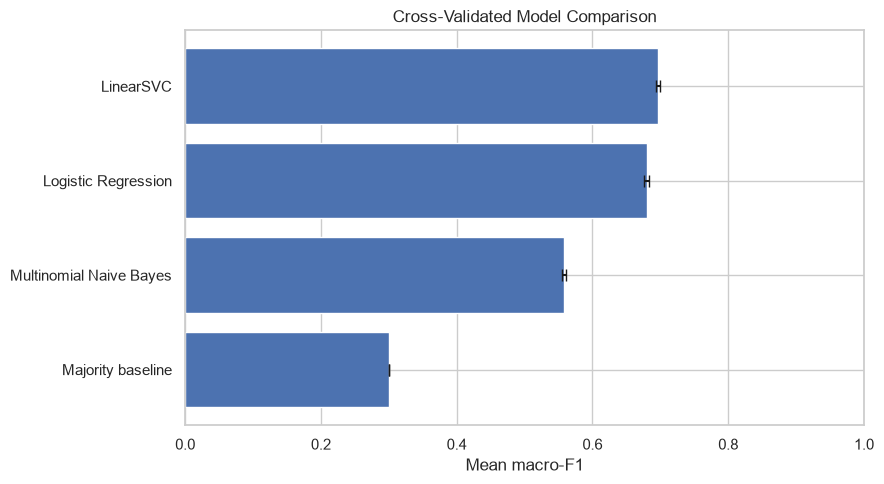

In [35]:
plot_df = cv_results.sort_values(
    "macro_f1_mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    plot_df["model"],
    plot_df["macro_f1_mean"],
    xerr=plot_df["macro_f1_std"],
    capsize=4
)

ax.set_title("Cross-Validated Model Comparison")
ax.set_xlabel("Mean macro-F1")
ax.set_xlim(0, 1)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

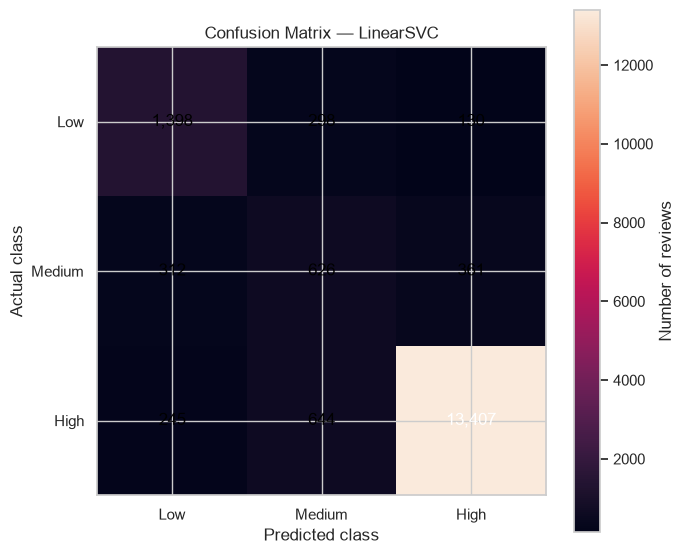

In [36]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation="nearest")

ax.set_title(f"Confusion Matrix — {selected_model_name}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

ax.set_xticks(range(len(CLASS_ORDER)))
ax.set_xticklabels(CLASS_ORDER)

ax.set_yticks(range(len(CLASS_ORDER)))
ax.set_yticklabels(CLASS_ORDER)

fig.colorbar(im, ax=ax, label="Number of reviews")

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

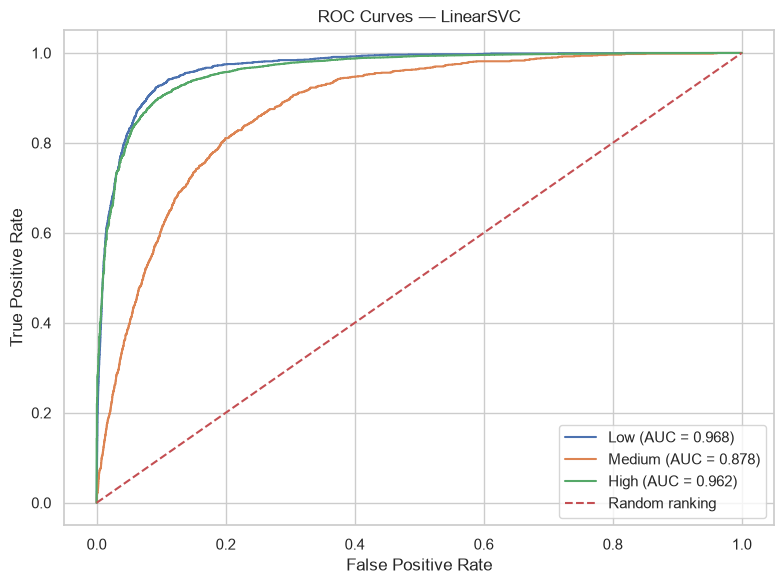

In [37]:
fig, ax = plt.subplots(figsize=(8, 6))

for cls in CLASS_ORDER:
    ax.plot(
        roc_data[cls]["fpr"],
        roc_data[cls]["tpr"],
        label=f"{cls} (AUC = {roc_data[cls]['auc']:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

ax.set_title(f"ROC Curves — {selected_model_name}")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week6_roc_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [38]:
prediction_df = pd.DataFrame({
    "review_text": X_test.reset_index(drop=True),
    "actual_class": y_test.reset_index(drop=True),
    "predicted_class": pd.Series(y_pred).reset_index(drop=True)
})

prediction_df["correct_prediction"] = (
    prediction_df["actual_class"]
    == prediction_df["predicted_class"]
)

errors_df = prediction_df[
    ~prediction_df["correct_prediction"]
].copy()

error_summary = (
    prediction_df
    .assign(is_error=~prediction_df["correct_prediction"])
    .groupby("actual_class", as_index=False)
    .agg(
        test_reviews=("actual_class", "size"),
        errors=("is_error", "sum")
    )
)

error_summary["error_rate_percentage"] = (
    error_summary["errors"]
    / error_summary["test_reviews"] * 100
).round(2)

display(error_summary)

errors_df.to_csv(
    OUTPUT_DIR / "week6_misclassified_reviews.csv",
    index=False
)

error_summary.to_csv(
    OUTPUT_DIR / "week6_error_analysis.csv",
    index=False
)

print("Misclassified reviews:", len(errors_df))
print("Error analysis saved.")

,actual_class,test_reviews,errors,error_rate_percentage
0,High,14296,889,6.22
1,Low,1826,428,23.44
2,Medium,1299,673,51.81


Misclassified reviews: 1990
Error analysis saved.


In [39]:
print("WEEK 6 EVALUATION COMPLETED")
print("=" * 45)

print("Selected model:", selected_model_name)
print("Test accuracy:", round(test_metrics["Accuracy"], 4))
print("Balanced accuracy:", round(test_metrics["Balanced_Accuracy"], 4))
print("Macro-F1:", round(test_metrics["Macro_F1"], 4))
print("Macro ROC-AUC:", round(macro_auc, 4))

print("\nFiles generated:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

print("\nOutput directory:")
print(OUTPUT_DIR.resolve())

WEEK 6 EVALUATION COMPLETED
Selected model: LinearSVC
Test accuracy: 0.8858
Balanced accuracy: 0.7284
Macro-F1: 0.7091
Macro ROC-AUC: 0.9357

Files generated:
week6_class_distribution.png
week6_confusion_matrix.csv
week6_confusion_matrix.png
week6_cross_validation_results.csv
week6_error_analysis.csv
week6_error_analysis_by_class.csv
week6_evaluation_metadata.json
week6_final_test_metrics.csv
week6_misclassified_reviews.csv
week6_model_comparison.png
week6_per_class_metrics.csv
week6_roc_auc_results.csv
week6_roc_curves.png

Output directory:
C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week6_outputs
